In [41]:
import xarray as xr
import glob
import pandas as pd
import numpy as np
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from cartopy.io.shapereader import Reader as ShapeReader

In [42]:
def read_mar_var(path_pattern, var_names, months=[11, 12, 1, 2, 3], time_slice=('19800101', '20220331')):
    """
    Reads MAR NetCDF files, selects specified variables and dimensions,
    filters by months and time range.

    Parameters:
        path_pattern (str): File path pattern for NetCDF files.
        var_names (list): List of variable names to extract.
        months (list, optional): Months to filter. Default is summer in Patagonia.
        time_slice (tuple, optional): Start and end date for filtering. Default is ('19800101', '20220331').

    Returns:
        xarray.Dataset: Concatenated and filtered dataset.
    """
    files = sorted(glob.glob(path_pattern))[-6:-2]
    ds_list = []

    for f in files:
        ds = xr.open_dataset(f).isel(ATMLAY3_3=0, SECTOR=0, SECTOR1_1=0)[var_names]
        ds = ds.sel(TIME=ds['TIME'].dt.month.isin(months))
        ds['TIME'] = ds['TIME'].dt.floor('D')
        ds_list.append(ds)

    ds_combined = xr.concat(ds_list, dim='TIME').sel(TIME=slice(*time_slice))
    return ds_combined


def read_mar_var_AP(path_pattern, var_names, months=[11, 12, 1, 2, 3], time_slice=('19800101', '20220331')):
    """
    Reads MAR NetCDF files, selects specified variables and dimensions,
    filters by months and time range.

    Parameters:
        path_pattern (str): File path pattern for NetCDF files.
        var_names (list): List of variable names to extract.
        months (list, optional): Months to filter. Default is summer in Patagonia.
        time_slice (tuple, optional): Start and end date for filtering. Default is ('19800101', '20220331').

    Returns:
        xarray.Dataset: Concatenated and filtered dataset.
    """
    files = sorted(glob.glob(path_pattern))[-4:]
    ds_list = []

    for f in files:
        ds = xr.open_dataset(f).sel(X = slice(-2660, -2120), Y= slice(800, 1700)).isel(SECTOR=0, SECTOR1_1=0, ATMLAY=0)[var_names]
        ds = ds.sel(TIME=ds['TIME'].dt.month.isin(months))
        ds['TIME'] = ds['TIME'].dt.floor('D')
        ds_list.append(ds)

    ds_combined = xr.concat(ds_list, dim='TIME').sel(TIME=slice(*time_slice))
    return ds_combined

def compute_daily_anomalies(ds: xr.DataArray, time_dim: str = "time") -> xr.DataArray:
    """
    Compute daily anomalies of a temperature field based on day-of-year climatology.
    
    Parameters:
        ds (xr.DataArray): Input data with a time dimension (e.g., daily temperature).
        time_dim (str): Name of the time dimension (default is 'time').

    Returns:
        anomalies (xr.DataArray): Daily anomalies with same shape as input.
    """

    # Create dayofyear coordinate
    doy = ds[time_dim].dt.dayofyear
    ds = ds.assign_coords(dayofyear=(time_dim, doy.data))

    # Compute climatology (mean for each day of the year)
    climatology = ds.groupby("dayofyear").mean(time_dim)

    # Subtract climatology to get anomalies
    anomalies = ds.groupby("dayofyear") - climatology

    return anomalies


In [43]:
files = sorted(glob.glob('/media/lacrio/TOSHIBA EXT/Postdoc_project/MAR_DATA_SEL/Patagonia/*.nc'))
ds_MAR = xr.open_dataset(files[0])
LAT = ds_MAR['LAT']
LON = ds_MAR['LON']

files = sorted(glob.glob('/media/lacrio/TOSHIBA EXT/Postdoc_project/MAR_DATA_SEL/APeninsula/*.nc'))
ds_MAR_AP = xr.open_dataset(files[0]).sel(X = slice(-2660, -2120), Y= slice(800, 1700))
LAT_AP = ds_MAR_AP['LAT']
LON_AP = ds_MAR_AP['LON']

In [44]:
with open('/home/lacrio/Postdoc_project/MAR_data/mask_PAT.npy', 'rb') as f:
    mask_PAT = np.load(f)

In [45]:
import cartopy.feature as cfeature
from shapely.geometry import Point
from shapely.prepared import prep

# --- Coastline polygons from Natural Earth (land) ---
land_feature = cfeature.NaturalEarthFeature("physical", "land", "10m")
land_geom = [prep(geom) for geom in land_feature.geometries()]

# --- Create coordinate grids ---
lon2d, lat2d = LON_AP, LAT_AP
mask_AP = np.zeros(lon2d.shape, dtype=bool)

# --- Build mask: True = continente
for i in range(lon2d.shape[0]):
    for j in range(lon2d.shape[1]):
        pt = Point(lon2d[i, j], lat2d[i, j])
        # True se está na terra
        if any(geom.contains(pt) for geom in land_geom):
            mask_AP[i, j] = True
        else:
            mask_AP[i, j] = False


# --- 🔧 Apply latitude limits (-68 ≤ lat ≤ -60)
#mask_AP[(lat2d < -68) | (lat2d > -60)] = False

In [46]:
def process_mar_patagonia(path_pattern, mask, spatial_dims=('Y25_370', 'X29_205')):
    """Procesa SEB para Patagonia usando SWU directo e incluye SWnet y LWnet."""
    ds_SWD = read_mar_var(path_pattern=path_pattern, var_names=['SWD']).where(mask)
    ds_SWU = read_mar_var(path_pattern=path_pattern, var_names=['SWU']).where(mask)
    ds_LWD = read_mar_var(path_pattern=path_pattern, var_names=['LWD']).where(mask)
    ds_LWU = read_mar_var(path_pattern=path_pattern, var_names=['LWU']).where(mask)
    ds_SHF = read_mar_var(path_pattern=path_pattern, var_names=['SHF']).where(mask)
    ds_LHF = read_mar_var(path_pattern=path_pattern, var_names=['LHF']).where(mask)

    # Componentes individuales
    swd = ds_SWD['SWD'].mean(spatial_dims).to_dataframe()['SWD']
    swu = (-1 * ds_SWU['SWU']).mean(spatial_dims).to_dataframe()['SWU']
    lwd = ds_LWD['LWD'].mean(spatial_dims).to_dataframe()['LWD']
    lwu = (-1 * ds_LWU['LWU']).mean(spatial_dims).to_dataframe()['LWU']
    shf = ds_SHF['SHF'].mean(spatial_dims).to_dataframe()['SHF']
    lhf = ds_LHF['LHF'].mean(spatial_dims).to_dataframe()['LHF']

    # Componentes NETOS
    swnet = (ds_SWD['SWD'] - ds_SWU['SWU']).mean(spatial_dims).to_dataframe(name='SWnet')['SWnet']
    lwnet = (ds_LWD['LWD'] - ds_LWU['LWU']).mean(spatial_dims).to_dataframe(name='LWnet')['LWnet']

    # Balance Neto Total (Qnet)
    qnet = (
        ds_SWD['SWD'] - ds_SWU['SWU'] + ds_LWD['LWD'] - ds_LWU['LWU'] + ds_SHF['SHF'] + ds_LHF['LHF']
    ).mean(spatial_dims).to_dataframe(name='Qnet')['Qnet']

    return pd.concat(
        [
            swd.rename("SWD"),
            swu.rename("SWU"),
            lwd.rename("LWD"),
            lwu.rename("LWU"),
            swnet.rename("SWnet"),
            lwnet.rename("LWnet"),
            shf.rename("SHF"),
            lhf.rename("LHF"),
            qnet,
        ],
        axis=1,
    )


def process_mar_apis(path_pattern, mask, spatial_dims=('Y', 'X')):
    """Procesa SEB para Península Antártica usando Albedo e incluye SWnet y LWnet."""
    ds_SWD = read_mar_var_AP(path_pattern=path_pattern, var_names=['SWD']).where(mask)
    ds_ALB = read_mar_var_AP(path_pattern=path_pattern, var_names=['AL']).where(mask)
    ds_LWD = read_mar_var_AP(path_pattern=path_pattern, var_names=['LWD']).where(mask)
    ds_LWU = read_mar_var_AP(path_pattern=path_pattern, var_names=['LWU']).where(mask)
    ds_SHF = read_mar_var_AP(path_pattern=path_pattern, var_names=['SHF']).where(mask)
    ds_LHF = read_mar_var_AP(path_pattern=path_pattern, var_names=['LHF']).where(mask)

    swd_da = ds_SWD['SWD']
    swu_da = -1 * (ds_SWD['SWD'] * ds_ALB['AL'])

    # Componentes individuales
    swd = swd_da.mean(spatial_dims).to_dataframe(name='SWD')['SWD']
    swu = swu_da.mean(spatial_dims).to_dataframe(name='SWU')['SWU']
    lwd = ds_LWD['LWD'].mean(spatial_dims).to_dataframe()['LWD']
    lwu = (-1 * ds_LWU['LWU']).mean(spatial_dims).to_dataframe()['LWU']
    shf = ds_SHF['SHF'].mean(spatial_dims).to_dataframe()['SHF']
    lhf = ds_LHF['LHF'].mean(spatial_dims).to_dataframe()['LHF']

    # Componentes NETOS (SWnet considerando albedo)
    swnet = (ds_SWD['SWD'] * (1 - ds_ALB['AL'])).mean(spatial_dims).to_dataframe(name='SWnet')['SWnet']
    lwnet = (ds_LWD['LWD'] - ds_LWU['LWU']).mean(spatial_dims).to_dataframe(name='LWnet')['LWnet']

    # Balance Neto Total (Qnet)
    qnet = (
        ds_SWD['SWD'] * (1 - ds_ALB['AL']) + ds_LWD['LWD'] - ds_LWU['LWU'] + ds_SHF['SHF'] + ds_LHF['LHF']
    ).mean(spatial_dims).to_dataframe(name='Qnet')['Qnet']

    return pd.concat(
        [
            swd.rename("SWD"),
            swu.rename("SWU"),
            lwd.rename("LWD"),
            lwu.rename("LWU"),
            swnet.rename("SWnet"),
            lwnet.rename("LWnet"),
            shf.rename("SHF"),
            lhf.rename("LHF"),
            qnet,
        ],
        axis=1,
    )

In [47]:
# =============================================================================
# 2. CARGA DE DATOS
# =============================================================================
path_patagonia = '/media/lacrio/TOSHIBA EXT/Postdoc_project/MAR_DATA_SEL/Patagonia/*.nc'
path_peninsula = '/media/lacrio/TOSHIBA EXT/Postdoc_project/MAR_DATA_SEL/APeninsula/*.nc'

# Ejecución de funciones
df_PIs = process_mar_patagonia(path_patagonia, mask_PAT, spatial_dims=('Y25_370', 'X29_205'))
df_APIS = process_mar_apis(path_peninsula, mask_AP, spatial_dims=('Y', 'X'))

df_patagonia = df_PIs
df_peninsula = df_APIS

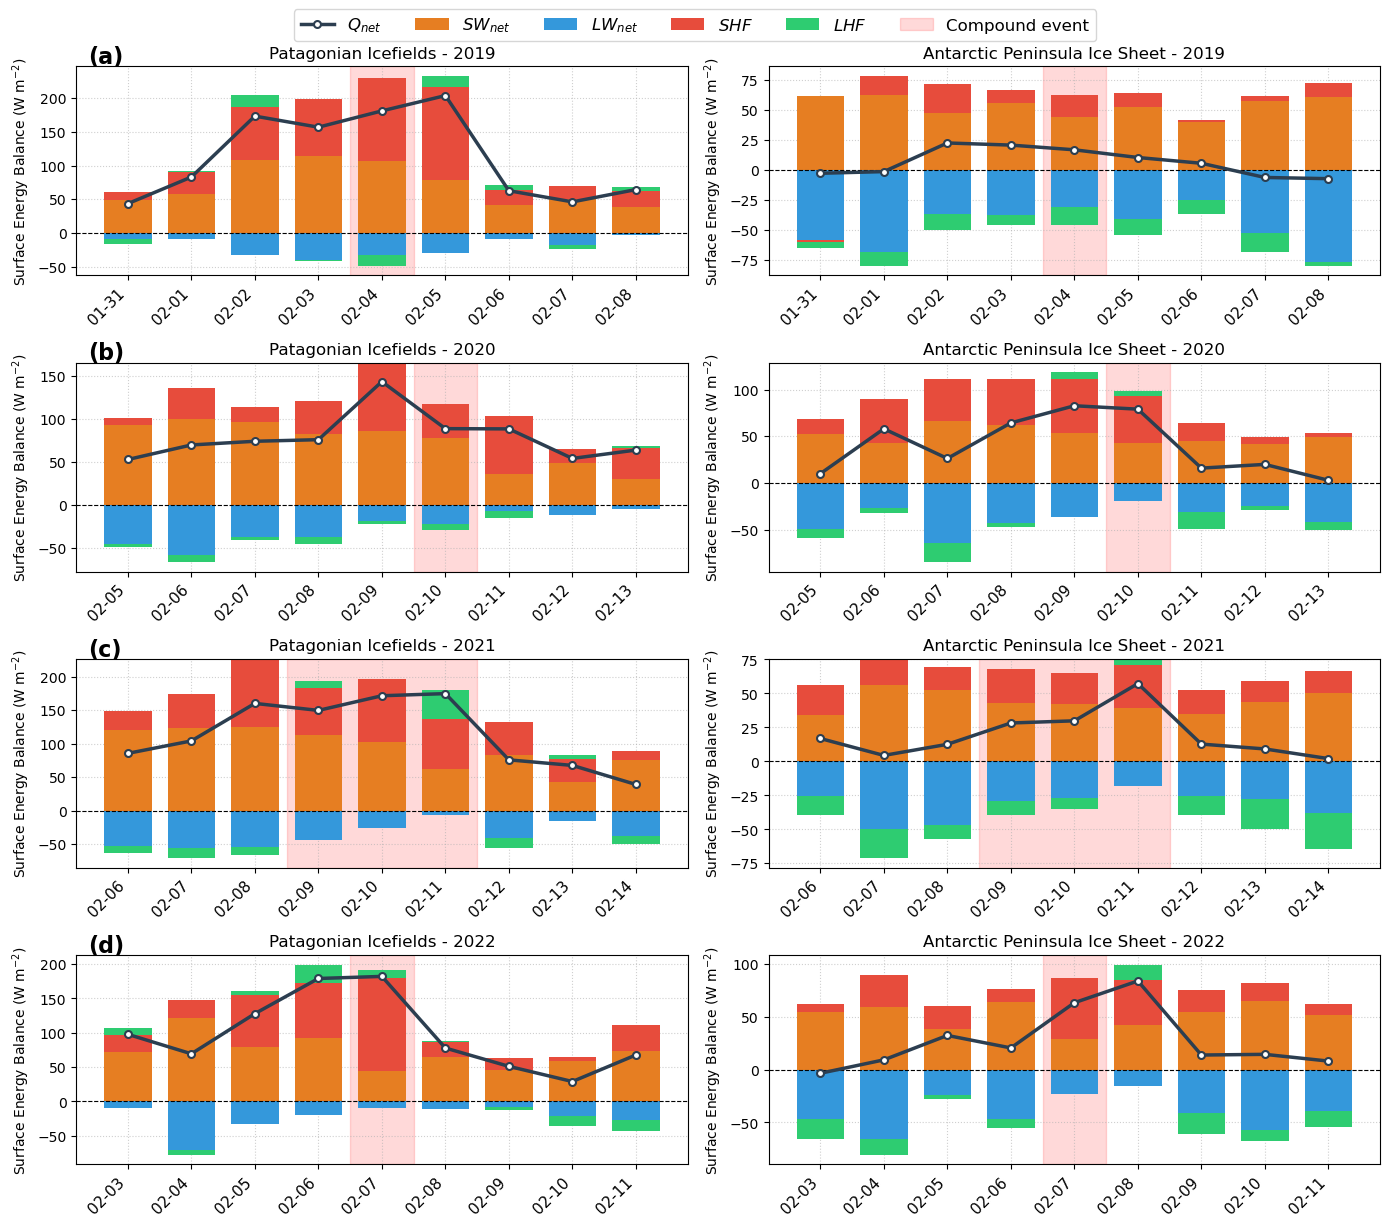

In [48]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df_patagonia = df_PIs
df_peninsula = df_APIS

# Componentes netas para las barras
components = ["SWnet", "LWnet", "SHF", "LHF"]

# Paleta de colores para los componentes netos
colors_dict = {
    "SWnet": "#e67e22",  # Naranja
    "LWnet": "#3498db",  # Azul
    "SHF": "#e74c3c",    # Rojo
    "LHF": "#2ecc71",    # Verde
    "Qnet": "#2c3e50",   # Azul oscuro / Negro
}

# Formato de etiquetas LaTeX
labels_dict = {
    "SWnet": r"$SW_{net}$",
    "LWnet": r"$LW_{net}$",
    "SHF": r"$SHF$",
    "LHF": r"$LHF$",
    "Qnet": r"$Q_{net}$",
}

# Configuración de rangos de fechas
date_ranges = [
    {
        "start": np.datetime64("2019-01-31"),
        "end": np.datetime64("2019-02-08"),
        "event_start": np.datetime64("2019-02-04"),
        "event_end": np.datetime64("2019-02-04"),
        "label": "2019",
    },
    {
        "start": np.datetime64("2020-02-05"),
        "end": np.datetime64("2020-02-13"),
        "event_start": np.datetime64("2020-02-10"),
        "event_end": np.datetime64("2020-02-10"),
        "label": "2020",
    },
    {
        "start": np.datetime64("2021-02-06"),
        "end": np.datetime64("2021-02-14"),
        "event_start": np.datetime64("2021-02-09"),
        "event_end": np.datetime64("2021-02-11"),
        "label": "2021",
    },
    {
        "start": np.datetime64("2022-02-03"),
        "end": np.datetime64("2022-02-11"),
        "event_start": np.datetime64("2022-02-07"),
        "event_end": np.datetime64("2022-02-07"),
        "label": "2022",
    },
]

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 12), sharey=False)
year_labels = ["(a)", "(b)", "(c)", "(d)"]

def plot_stacked_seb(ax, df_slice):
    x = np.arange(len(df_slice))
    width = 0.75

    bottom_pos = np.zeros(len(df_slice))
    bottom_neg = np.zeros(len(df_slice))

    # Barras apiladas para cada componente NETO
    for comp in components:
        if comp in df_slice.columns:
            values = df_slice[comp].values
            pos_vals = np.where(values > 0, values, 0)
            neg_vals = np.where(values < 0, values, 0)

            label_text = labels_dict.get(comp, comp)

            if np.any(pos_vals > 0):
                ax.bar(
                    x,
                    pos_vals,
                    width=width,
                    bottom=bottom_pos,
                    color=colors_dict.get(comp, "gray"),
                    label=label_text,
                    zorder=2,
                )
                bottom_pos += pos_vals

            if np.any(neg_vals < 0):
                ax.bar(
                    x,
                    neg_vals,
                    width=width,
                    bottom=bottom_neg,
                    color=colors_dict.get(comp, "gray"),
                    label=label_text,
                    zorder=2,
                )
                bottom_neg += neg_vals

    # Línea con puntos destacada para Qnet
    if "Qnet" in df_slice.columns:
        ax.plot(
            x,
            df_slice["Qnet"],
            color=colors_dict.get("Qnet", "black"),
            linewidth=2.5,
            marker="o",
            markersize=5,
            mfc="white",
            mew=1.5,
            label=labels_dict["Qnet"],
            zorder=4,
        )

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(df_slice.index.strftime("%m-%d"), rotation=45, ha="right", fontsize=11)
    ax.grid(True, linestyle=":", alpha=0.6, zorder=1)


for i, rng in enumerate(date_ranges):
    start, end = rng["start"], rng["end"]
    event_start, event_end = rng["event_start"], rng["event_end"]

    # Filtrar datos por rango de fechas
    pat_slice = df_patagonia.loc[start:end]
    pen_slice = df_peninsula.loc[start:end]

    # Panel Izquierdo: Patagonia
    plot_stacked_seb(axes[i, 0], pat_slice)
    axes[i, 0].set_title(f"Patagonian Icefields - {rng['label']}")
    axes[i, 0].set_ylabel("Surface Energy Balance (W m$^{-2}$)")

    # Panel Derecho: Península Antártica
    plot_stacked_seb(axes[i, 1], pen_slice)
    axes[i, 1].set_title(f"Antarctic Peninsula Ice Sheet - {rng['label']}")
    axes[i, 1].set_ylabel("Surface Energy Balance (W m$^{-2}$)")

    # Sombreado vertical del evento
    time_index = pat_slice.index
    start_idx = np.where(time_index == event_start)[0][0]
    end_idx = np.where(time_index == event_end)[0][0]

    vspan_handle = axes[i, 0].axvspan(start_idx - 0.5, end_idx + 0.5, color="red", alpha=0.15, zorder=0)
    axes[i, 1].axvspan(start_idx - 0.5, end_idx + 0.5, color="red", alpha=0.15, zorder=0)

    # Etiqueta del subpanel (a, b, c, d)
    axes[i, 0].text(
        0.02,
        1.10,
        year_labels[i],
        transform=axes[i, 0].transAxes,
        fontsize=16,
        fontweight="bold",
        va="top",
    )

# Extracción de handles para la leyenda unificada
handles_dict = {}
for ax in axes.flat:
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label not in handles_dict:
            handles_dict[label] = handle

handles_dict["Compound event"] = vspan_handle

# Leyenda global
fig.legend(
    handles_dict.values(),
    handles_dict.keys(),
    loc="upper center",
    ncol=len(handles_dict),
    bbox_to_anchor=(0.5, 1.025),
    frameon=True,
    fontsize=12,
)

plt.tight_layout()

# Guardar figura
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "SEB_cases_net.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()
#plt.close(fig)

In [49]:
import numpy as np
import pandas as pd

# 1. Definir los componentes del SEB a incluir
seb_vars = ["SWD", "SWU", "SWnet", "LWD", "LWU", "LWnet", "SHF", "LHF", "Qnet"]

events_seb = [
    {"year": 2019, "end_date": "2019-02-04"},
    {"year": 2020, "end_date": "2020-02-10"},
    {"year": 2021, "end_date": "2021-02-10"},
    {"year": 2022, "end_date": "2022-02-07"},
]

# 2. Asegurar DatetimeIndex
df_PIs_clean = df_PIs.copy()
df_APIS_clean = df_APIS.copy()

df_PIs_clean.index = pd.to_datetime(df_PIs_clean.index)
df_APIS_clean.index = pd.to_datetime(df_APIS_clean.index)

# Filtrar solo variables SEB existentes
df_PIs_clean = df_PIs_clean[[c for c in seb_vars if c in df_PIs_clean.columns]]
df_APIS_clean = df_APIS_clean[[c for c in seb_vars if c in df_APIS_clean.columns]]

# 3. Construir subsets por eventos
selected_subsets_seb = []

for event in events_seb:
    year = event["year"]
    end_date = pd.to_datetime(event["end_date"])
    start_date = end_date - pd.Timedelta(days=2)

    pat_sub = df_PIs_clean.loc[start_date:end_date].copy()
    pat_sub.index = pd.MultiIndex.from_product([[year], pat_sub.index], names=["Year", "Date"])

    pen_sub = df_APIS_clean.loc[start_date:end_date].copy()
    pen_sub.index = pd.MultiIndex.from_product([[year], pen_sub.index], names=["Year", "Date"])

    combined_year = pd.concat(
        [pat_sub, pen_sub],
        axis=1,
        keys=["Patagonian Icefields", "Antarctic Peninsula Ice Sheet"],
        names=["Region", "Variable"],
    )

    selected_subsets_seb.append(combined_year)

# 4. Concatenar y aplicar formato estricto de 2 decimales
table_seb_selected = pd.concat(selected_subsets_seb)

# Opción A: Mantenerlos como números pero formatear la visualización en consola
pd.set_option('display.float_format', lambda x: '%.0f' % x)

# Opción B (Opcional): Si quieres que las celdas sean texto estricto con 2 decimales:
# table_seb_selected = table_seb_selected.applymap(lambda x: f"{x:.2f}" if isinstance(x, (int, float)) else x)

(table_seb_selected)

# Al exportar a Excel o CSV mantendrá los valores numéricos limpios con .round(2)
# table_seb_selected.round(2).to_excel("SEB_components_selected.xlsx")
# table_seb_selected.round(2).to_csv("SEB_components_selected.csv")

Region          Patagonian Icefields                                         \
Variable                         SWD  SWU SWnet LWD  LWU LWnet SHF LHF Qnet   
Year Date                                                                     
2019 2019-02-02                  332 -224   108 287 -319   -32  79  18  173   
     2019-02-03                  346 -232   114 279 -319   -40  84  -1  157   
     2019-02-04                  321 -215   107 286 -319   -32 123 -16  181   
2020 2020-02-08                  255 -172    83 275 -312   -37  38  -8   76   
     2020-02-09                  247 -161    86 300 -319   -19  80  -3  144   
     2020-02-10                  232 -154    78 295 -318   -22  39  -6   89   
2021 2021-02-08                  340 -216   124 264 -318   -54 102 -13  160   
     2021-02-09                  317 -203   113 275 -319   -44  70  10  150   
     2021-02-10                  285 -183   102 294 -319   -25  94   0  172   
2022 2022-02-05                  238 -158    80 280 -314   -34  76   6  128   
     2022-02-06                  258 -166    92 299 -319   -20  80  27  179   
     2022-02-07                  132  -89    44 309 -319    -9 136  11  182   

Region          Antarctic Peninsula Ice Sheet                                \
Variable                                  SWD  SWU SWnet LWD  LWU LWnet SHF   
Year Date                                                                     
2019 2019-02-02                           223 -175    47 264 -301   -37  25   
     2019-02-03                           247 -191    56 271 -308   -37  10   
     2019-02-04                           192 -148    44 274 -305   -31  19   
2020 2020-02-08                           240 -178    62 270 -313   -43  50   
     2020-02-09                           199 -146    53 278 -314   -36  58   
     2020-02-10                           159 -116    43 295 -315   -19  50   
2021 2021-02-08                           227 -174    53 249 -296   -47  17   
     2021-02-09                           173 -130    43 278 -307   -29  25   
     2021-02-10                           155 -113    42 280 -307   -27  23   
2022 2022-02-05                           168 -130    38 285 -309   -24  22   
     2022-02-06                           268 -204    64 262 -309   -47  12   
     2022-02-07                           118  -89    29 287 -310   -23  58   

Region                    
Variable        LHF Qnet  
Year Date                 
2019 2019-02-02 -13   23  
     2019-02-03  -8   21  
     2019-02-04 -15   17  
2020 2020-02-08  -4   64  
     2020-02-09   7   83  
     2020-02-10   5   79  
2021 2021-02-08 -10   13  
     2021-02-09 -10   28  
     2021-02-10  -8   30  
2022 2022-02-05  -3   32  
     2022-02-06  -9   21  
     2022-02-07  -0   63

In [62]:
def process_mar_patagonia(path_pattern, mask, spatial_dims=('Y25_370', 'X29_205')):
    """Procesa las componentes del SMB para Patagonia agrupando SF y RF en Precipitación (PR)."""
    ds_SF  = read_mar_var(path_pattern=path_pattern, var_names=['SF']).where(mask)
    ds_RF  = read_mar_var(path_pattern=path_pattern, var_names=['RF']).where(mask)
    ds_SU  = read_mar_var(path_pattern=path_pattern, var_names=['SU']).where(mask)
    ds_RU  = read_mar_var(path_pattern=path_pattern, var_names=['RU']).where(mask)
    ds_ME  = read_mar_var(path_pattern=path_pattern, var_names=['ME']).where(mask)
    ds_SMB_var = read_mar_var(path_pattern=path_pattern, var_names=['SMB']).where(mask)
    ds_PR = ds_SF['SF'] + ds_RF['RF']

    #ds_RE = (ds_PR - ds_RU['RU'] - ds_SU['SU'] - ds_SMB['SMB']).clip(min=0)
    ds_RE = (ds_ME['ME'] + ds_RF['RF'] - ds_RU['RU']).clip(min=0) # 

    #ds_SMB = ds_PR + ds_RE - ds_RU['RU'] - ds_SU['SU']
    #ds_SMB = ds_PR + ds_RE - ds_ME['ME'] - ds_RF['RF'] - ds_SU['SU']
    ds_SMB = ds_SF['SF'] + ds_RE - ds_ME['ME'] - ds_SU['SU']


    # Precipitación total PR = SF + RF (Entrada de masa positiva)
    pr = ds_PR.mean(spatial_dims).to_dataframe(name='PR')['PR']

    re = ds_RE.mean(spatial_dims).to_dataframe(name='RZ')['RZ']

    # Salidas de masa (se consideran negativas)
    su = (-1 * ds_SU['SU']).mean(spatial_dims).to_dataframe()['SU']
    ru = (-1 * ds_RU['RU']).mean(spatial_dims).to_dataframe()['RU']
    me = (-1 * ds_ME['ME']).mean(spatial_dims).to_dataframe()['ME']
    rf = (ds_RF['RF']).mean(spatial_dims).to_dataframe()['RF']
    sf = ds_SF['SF'].mean(spatial_dims).to_dataframe()['SF']
    smb_var = ds_SMB_var['SMB'].mean(spatial_dims).to_dataframe()['SMB']
    smb = ds_SMB.mean(spatial_dims).to_dataframe(name='SMB')['SMB']

    return pd.concat(
        [
            sf.rename("SF"),
            rf.rename("RF"),
            pr.rename("PR"),
            re.rename("RZ"),
            ru.rename("RU"),
            su.rename("SU"),
            me.rename("ME"),
            smb,
            smb_var.rename("SMB_mar"),
            
        ],
        axis=1,
    )


def process_mar_apis(path_pattern, mask, spatial_dims=('Y', 'X')):
    """Procesa las componentes del SMB para la Península Antártica agrupando SF y RF en Precipitación (PR)."""
    ds_SF  = read_mar_var_AP(path_pattern=path_pattern, var_names=['SF']).where(mask)
    ds_RF  = read_mar_var_AP(path_pattern=path_pattern, var_names=['RF']).where(mask)
    ds_SU  = read_mar_var_AP(path_pattern=path_pattern, var_names=['SU']).where(mask)
    ds_RU  = read_mar_var_AP(path_pattern=path_pattern, var_names=['RU']).where(mask)
    ds_ME  = read_mar_var_AP(path_pattern=path_pattern, var_names=['ME']).where(mask)
    #ds_RZ  = read_mar_var_AP(path_pattern=path_pattern, var_names=['RZ']).where(mask)
    
    ds_SMB_var = read_mar_var_AP(path_pattern=path_pattern, var_names=['SMB']).where(mask)
    ds_PR = ds_SF['SF'] + ds_RF['RF']

    #ds_RE = (ds_PR - ds_RU['RU'] - ds_SU['SU'] - ds_SMB['SMB']).clip(min=0)
    ds_RE = (ds_ME['ME'] + ds_RF['RF'] - ds_RU['RU']).clip(min=0) # 

#    ds_SMB = ds_PR + ds_RE - ds_ME['ME'] - ds_RF['RF'] - ds_SU['SU']
    ds_SMB = ds_SF['SF'] + ds_RE - ds_ME['ME'] - ds_SU['SU']


    # Precipitación total PR = SF + RF (Entrada de masa positiva)
    pr = ds_PR.mean(spatial_dims).to_dataframe(name='PR')['PR']

    re = ds_RE.mean(spatial_dims).to_dataframe(name='RE')['RE']
    #re  = ds_RZ['RZ'].mean(spatial_dims).to_dataframe()['RZ']

    # Salidas de masa (se consideran negativas)
    su = (-1 * ds_SU['SU']).mean(spatial_dims).to_dataframe()['SU']
    ru = (-1 * ds_RU['RU']).mean(spatial_dims).to_dataframe()['RU']
    me = (-1 * ds_ME['ME']).mean(spatial_dims).to_dataframe()['ME']
    rf = (ds_RF['RF']).mean(spatial_dims).to_dataframe()['RF']
    sf = ds_SF['SF'].mean(spatial_dims).to_dataframe()['SF']
    smb_var = ds_SMB_var['SMB'].mean(spatial_dims).to_dataframe()['SMB']
    smb = ds_SMB.mean(spatial_dims).to_dataframe(name='SMB')['SMB']

    return pd.concat(
        [
            sf.rename("SF"),
            rf.rename("RF"),
            pr.rename("PR"),
            re.rename("RZ"),
            ru.rename("RU"),
            su.rename("SU"),
            me.rename("ME"),
            smb,
            smb_var.rename("SMB_mar"),

        ],
        axis=1,
    )


In [63]:
# =============================================================================
# 2. CARGA DE DATOS
# =============================================================================
path_patagonia = '/media/lacrio/TOSHIBA EXT/Postdoc_project/MAR_DATA_SEL/Patagonia/*.nc'
path_peninsula = '/media/lacrio/TOSHIBA EXT/Postdoc_project/MAR_DATA_SEL/APeninsula/*.nc'

# Ejecución de funciones
df_PIs = process_mar_patagonia(path_patagonia, mask_PAT, spatial_dims=('Y25_370', 'X29_205'))
df_APIS = process_mar_apis(path_peninsula, mask_AP, spatial_dims=('Y', 'X'))

df_patagonia = df_PIs
df_peninsula = df_APIS

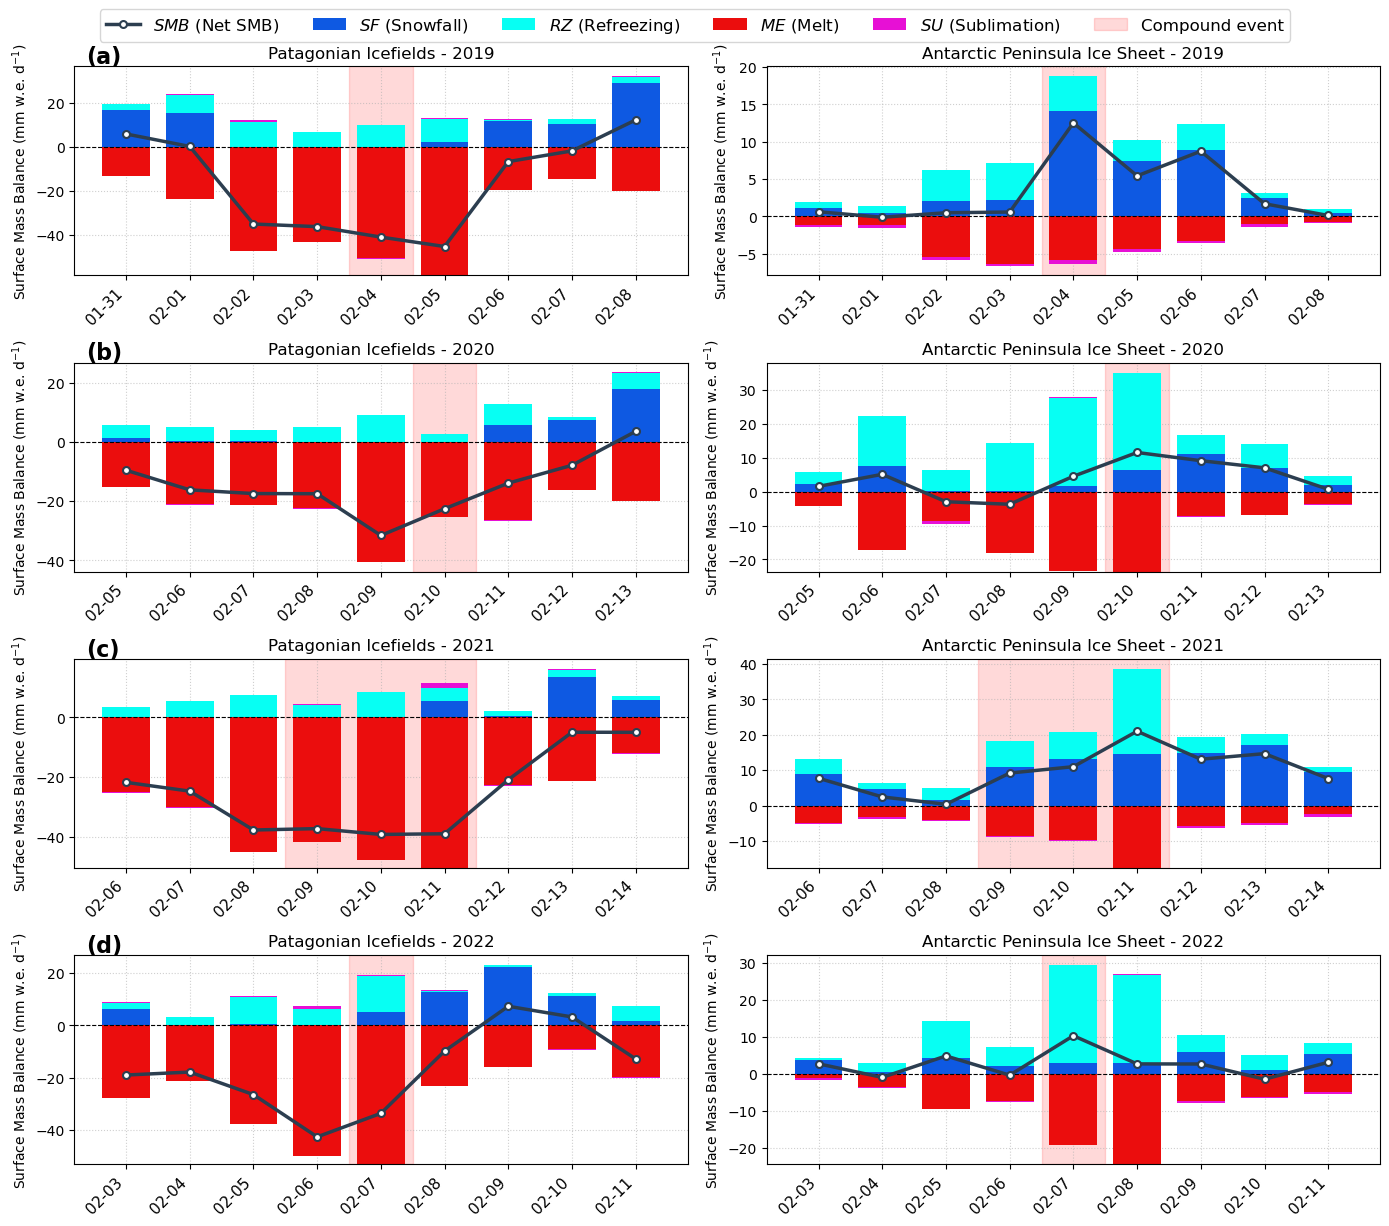

In [65]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df_patagonia = df_PIs
df_peninsula = df_APIS

# Componentes del SMB solicitados para las barras apiladas
bar_components = ["SF", "RZ", "ME", "SU"]

# Paleta de colores personalizada según tus indicaciones
colors_dict = {
    "SF": "#0e59e2",   # Azul (Rainfall / Precipitación líquida)
    "RZ": "#07fff3",   # Celeste (Refreezing)
    "ME": "#eb0d0d",   # Rojo (Melt)
    "SU": "#e710d5",   # Morado (Sublimation)
    "SMB": "#2c3e50",  # Azul oscuro / Negro (Net SMB)
}

# Formato de etiquetas LaTeX para la leyenda
labels_dict = {
    "SF": r"$SF$ (Snowfall)",
    "RZ": r"$RZ$ (Refreezing)",
    "ME": r"$ME$ (Melt)",
    "SU": r"$SU$ (Sublimation)",
    "SMB": r"$SMB$ (Net SMB)",
}

# Configuración de rangos de fechas (eventos)
date_ranges = [
    {
        "start": np.datetime64("2019-01-31"),
        "end": np.datetime64("2019-02-08"),
        "event_start": np.datetime64("2019-02-04"),
        "event_end": np.datetime64("2019-02-04"),
        "label": "2019",
    },
    {
        "start": np.datetime64("2020-02-05"),
        "end": np.datetime64("2020-02-13"),
        "event_start": np.datetime64("2020-02-10"),
        "event_end": np.datetime64("2020-02-10"),
        "label": "2020",
    },
    {
        "start": np.datetime64("2021-02-06"),
        "end": np.datetime64("2021-02-14"),
        "event_start": np.datetime64("2021-02-09"),
        "event_end": np.datetime64("2021-02-11"),
        "label": "2021",
    },
    {
        "start": np.datetime64("2022-02-03"),
        "end": np.datetime64("2022-02-11"),
        "event_start": np.datetime64("2022-02-07"),
        "event_end": np.datetime64("2022-02-07"),
        "label": "2022",
    },
]

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 12), sharey=False)
year_labels = ["(a)", "(b)", "(c)", "(d)"]

def plot_stacked_smb(ax, df_slice):
    x = np.arange(len(df_slice))
    width = 0.75

    bottom_pos = np.zeros(len(df_slice))
    bottom_neg = np.zeros(len(df_slice))

    # Barras apiladas para los componentes seleccionados del SMB
    for comp in bar_components:
        if comp in df_slice.columns:
            values = df_slice[comp].values
            pos_vals = np.where(values > 0, values, 0)
            neg_vals = np.where(values < 0, values, 0)

            label_text = labels_dict.get(comp, comp)

            if np.any(pos_vals > 0):
                ax.bar(
                    x,
                    pos_vals,
                    width=width,
                    bottom=bottom_pos,
                    color=colors_dict.get(comp, "gray"),
                    label=label_text,
                    zorder=2,
                )
                bottom_pos += pos_vals

            if np.any(neg_vals < 0):
                ax.bar(
                    x,
                    neg_vals,
                    width=width,
                    bottom=bottom_neg,
                    color=colors_dict.get(comp, "gray"),
                    label=label_text,
                    zorder=2,
                )
                bottom_neg += neg_vals

    # Línea destacada para el SMB Neto
    if "SMB" in df_slice.columns:
        ax.plot(
            x,
            df_slice["SMB"],
            color=colors_dict.get("SMB", "black"),
            linewidth=2.5,
            marker="o",
            markersize=5,
            mfc="white",
            mew=1.5,
            label=labels_dict["SMB"],
            zorder=4,
        )

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(df_slice.index.strftime("%m-%d"), rotation=45, ha="right", fontsize=11)
    ax.grid(True, linestyle=":", alpha=0.6, zorder=1)


for i, rng in enumerate(date_ranges):
    start, end = rng["start"], rng["end"]
    event_start, event_end = rng["event_start"], rng["event_end"]

    # Filtrar datos por rango de fechas
    pat_slice = df_patagonia.loc[start:end].copy()
    pen_slice = df_peninsula.loc[start:end].copy()

    # Panel Izquierdo: Patagonia
    plot_stacked_smb(axes[i, 0], pat_slice)
    axes[i, 0].set_title(f"Patagonian Icefields - {rng['label']}")
    axes[i, 0].set_ylabel("Surface Mass Balance (mm w.e. d$^{-1}$)")

    # Panel Derecho: Península Antártica
    plot_stacked_smb(axes[i, 1], pen_slice)
    axes[i, 1].set_title(f"Antarctic Peninsula Ice Sheet - {rng['label']}")
    axes[i, 1].set_ylabel("Surface Mass Balance (mm w.e. d$^{-1}$)")

    # Sombreado vertical del evento compuesto
    time_index = pat_slice.index
    start_idx = np.where(time_index == event_start)[0][0]
    end_idx = np.where(time_index == event_end)[0][0]

    vspan_handle = axes[i, 0].axvspan(start_idx - 0.5, end_idx + 0.5, color="red", alpha=0.15, zorder=0)
    axes[i, 1].axvspan(start_idx - 0.5, end_idx + 0.5, color="red", alpha=0.15, zorder=0)

    # Etiqueta del subpanel (a, b, c, d)
    axes[i, 0].text(
        0.02,
        1.10,
        year_labels[i],
        transform=axes[i, 0].transAxes,
        fontsize=16,
        fontweight="bold",
        va="top",
    )

# Extracción de handles para la leyenda unificada
handles_dict = {}
for ax in axes.flat:
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label not in handles_dict:
            handles_dict[label] = handle

handles_dict["Compound event"] = vspan_handle

# Leyenda global superior
fig.legend(
    handles_dict.values(),
    handles_dict.keys(),
    loc="upper center",
    ncol=len(handles_dict),
    bbox_to_anchor=(0.5, 1.025),
    frameon=True,
    fontsize=12,
)

plt.tight_layout()

# Guardar figura
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "SMB_cases_stacked.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

In [66]:
import pandas as pd
import numpy as np

# 1. Definir las variables del SMB
smb_vars = ["SF", "ME", "RZ", "SU", "SMB", "RU", "RF",]

events_smb = [
    {"year": 2019, "end_date": "2019-02-04"},
    {"year": 2020, "end_date": "2020-02-10"},
    {"year": 2021, "end_date": "2021-02-10"},
    {"year": 2022, "end_date": "2022-02-07"},
]

# 2. Copia limpia de los DataFrames y conversión a DatetimeIndex
df_PIs_clean = df_PIs.copy()
df_APIS_clean = df_APIS.copy()

df_PIs_clean.index = pd.to_datetime(df_PIs_clean.index)
df_APIS_clean.index = pd.to_datetime(df_APIS_clean.index)

# 3. Asegurar la presencia de 'PR' en caso de llamarse PRECP o SF+RF
for df_c in [df_PIs_clean, df_APIS_clean]:
    if "PR" not in df_c.columns:
        if "PRECP" in df_c.columns:
            df_c["PR"] = df_c["PRECP"]
        elif "SF" in df_c.columns and "RF" in df_c.columns:
            df_c["PR"] = df_c["SF"] + df_c["RF"]

# Filtrar solo las variables del SMB presentes
df_PIs_clean = df_PIs_clean[[c for c in smb_vars if c in df_PIs_clean.columns]]
df_APIS_clean = df_APIS_clean[[c for c in smb_vars if c in df_APIS_clean.columns]]

# 4. Construir subconjuntos por evento (2 días antes hasta la fecha del evento)
selected_subsets_smb = []

for event in events_smb:
    year = event["year"]
    end_date = pd.to_datetime(event["end_date"])
    start_date = end_date - pd.Timedelta(days=2)

    # Rebanar y asignar MultiIndex (Year, Date)
    pat_sub = df_PIs_clean.loc[start_date:end_date].copy()
    pat_sub.index = pd.MultiIndex.from_product([[year], pat_sub.index], names=["Year", "Date"])

    pen_sub = df_APIS_clean.loc[start_date:end_date].copy()
    pen_sub.index = pd.MultiIndex.from_product([[year], pen_sub.index], names=["Year", "Date"])

    # Unir regiones horizontalmente (Patagonia primero, APIS después)
    combined_year = pd.concat(
        [pat_sub, pen_sub],
        axis=1,
        keys=["Patagonian Icefields", "Antarctic Peninsula Ice Sheet"],
        names=["Region", "Variable"],
    )

    selected_subsets_smb.append(combined_year)

# 5. Concatenar todos los eventos
table_smb_selected = pd.concat(selected_subsets_smb)

# Configuración para forzar la visualización estricta de 2 decimales en pantalla
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Mostrar la tabla formateada
table_smb_selected

# Opcional: Exportar a Excel o CSV redondeado a 2 decimales
# table_smb_selected.round(2).to_excel("SMB_components_selected.xlsx")
# table_smb_selected.round(2).to_csv("SMB_components_selected.csv")

Region          Patagonian Icefields                                         \
Variable                          SF     ME    RZ    SU    SMB     RU    RF   
Year Date                                                                     
2019 2019-02-02                 0.04 -47.25 11.33  0.72 -35.15 -37.75  1.55   
     2019-02-03                 0.00 -43.25  6.83  0.09 -36.34 -37.59  0.01   
     2019-02-04                 0.00 -50.55  9.86 -0.41 -41.10 -40.95  0.00   
2020 2020-02-08                 0.00 -22.43  5.14 -0.18 -17.47 -17.43  0.00   
     2020-02-09                 0.15 -40.59  8.89 -0.02 -31.58 -33.66  1.92   
     2020-02-10                 0.04 -25.20  2.73 -0.12 -22.54 -25.55  0.21   
2021 2021-02-08                 0.00 -44.91  7.53 -0.31 -37.70 -37.45  0.00   
     2021-02-09                 0.00 -41.81  4.15  0.42 -37.23 -38.98  0.04   
     2021-02-10                 0.00 -47.64  8.37  0.09 -39.18 -39.32  0.00   
2022 2022-02-05                 0.63 -37.40 10.08  0.31 -26.38 -29.78  2.36   
     2022-02-06                 0.09 -49.90  6.31  1.00 -42.50 -45.58  1.16   
     2022-02-07                 5.13 -52.92 13.76  0.50 -33.53 -58.18 18.96   

Region          Antarctic Peninsula Ice Sheet                                 \
Variable                                   SF     ME    RZ    SU   SMB    RU   
Year Date                                                                      
2019 2019-02-02                          2.06  -5.39  4.21 -0.38  0.50 -1.53   
     2019-02-03                          2.17  -6.38  5.05 -0.25  0.59 -2.22   
     2019-02-04                         14.17  -5.84  4.65 -0.46 12.52 -2.91   
2020 2020-02-08                          0.19 -18.11 14.34 -0.12 -3.70 -4.28   
     2020-02-09                          1.57 -23.49 26.26  0.23  4.58 -6.29   
     2020-02-10                          6.55 -23.63 28.50  0.18 11.61 -8.11   
2021 2021-02-08                          1.58  -4.19  3.25 -0.30  0.34 -1.92   
     2021-02-09                         10.85  -8.66  7.29 -0.31  9.18 -5.68   
     2021-02-10                         13.12  -9.68  7.78 -0.24 10.99 -6.28   
2022 2022-02-05                          4.31  -9.35 10.03 -0.10  4.89 -4.37   
     2022-02-06                          2.06  -7.31  5.19 -0.24 -0.31 -3.75   
     2022-02-07                          3.05 -19.08 26.36  0.02 10.35 -8.22   

Region                 
Variable           RF  
Year Date              
2019 2019-02-02  0.34  
     2019-02-03  0.88  
     2019-02-04  1.71  
2020 2020-02-08  0.51  
     2020-02-09  9.05  
     2020-02-10 12.97  
2021 2021-02-08  0.97  
     2021-02-09  4.31  
     2021-02-10  4.38  
2022 2022-02-05  5.04  
     2022-02-06  1.61  
     2022-02-07 15.49